In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import os
import glob as glob

import sqlite3 

In [22]:
data_parent_dir = '/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL/sqlite_L3/'
dataset_ids = ['new_190311']#, 'new_190312', 'new_190313', 'new_190314']
background_ids =  ['oscNext']

dataset_paths = []
for did in dataset_ids:
    dataset_paths.extend(glob.glob(os.path.join(data_parent_dir, "{}".format(did), "merged/merged.db")))

background_paths = []
for did in background_ids:
    background_paths.extend(glob.glob(os.path.join(data_parent_dir, "{}".format(did), "merged/merged.db")))
 

In [23]:
print(background_paths)
print(dataset_paths)

[]
['/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL/sqlite_L3/new_190311/merged/merged.db']


In [24]:
# create connection to the database 
connection = sqlite3.connect(dataset_paths[0]) 
# background_conn = sqlite3.connect(background_paths[0])
# query to display all data in the table 
# cursor = connection.execute("SELECT * from truth") 

sql_query="SELECT * from truth"

db = pd.read_sql(sql_query, connection)
db.head()

,energy,position_x,position_y,position_z,azimuth,zenith,pid,event_time,sim_type,interaction_type,...,CascadeFilter_13,MuonFilter_13,OnlineL2Filter_17,L3_oscNext_bool,L4_oscNext_bool,L5_oscNext_bool,L6_oscNext_bool,L7_oscNext_bool,event_weight,event_no
0,75.851528,-49.803365,-3.416929,-379.072893,3.155978,1.746711,16.0,1.087909e+17,NuGen,-1.0,...,1.0,1.0,1.0,1.0,-1.0,-1.0,-1.0,-1.0,8.655629e-16,0
1,35.806381,-250.902067,-8.492302,-350.670129,1.958171,2.035593,16.0,1.087909e+17,NuGen,-1.0,...,0.0,0.0,0.0,0.0,-1.0,-1.0,-1.0,-1.0,7.333098e-15,1
2,44.064114,-96.846286,154.015374,-410.127411,1.466318,2.048718,16.0,1.087909e+17,NuGen,-1.0,...,0.0,0.0,0.0,0.0,-1.0,-1.0,-1.0,-1.0,6.962244e-17,2
3,128.712004,53.265014,24.293776,-387.161004,6.191010,1.833890,16.0,1.087909e+17,NuGen,-1.0,...,1.0,1.0,1.0,1.0,-1.0,-1.0,-1.0,-1.0,4.650600e-16,3
4,14.762710,86.900392,-98.873370,-367.065016,3.303594,2.594001,16.0,1.087909e+17,NuGen,-1.0,...,0.0,0.0,0.0,0.0,-1.0,-1.0,-1.0,-1.0,3.664927e-14,4


In [45]:
db['hnl_decay_mode']

0       -1.0
1       -1.0
2       -1.0
3       -1.0
4       -1.0
        ... 
15847   -1.0
15848   -1.0
15849   -1.0
15850   -1.0
15851   -1.0
Name: hnl_decay_mode, Length: 15852, dtype: float64

In [38]:
from I3Tray import I3Tray
from icecube import icetray, dataio, dataclasses, simclasses

# try: from tqdm import tqdm
# except: tqdm = lambda x: x
    
def get_decay_mode(file):
    
    i3file = dataio.I3File(file)

    # And loop through frames for this file
    while i3file.more():
        frame = i3file.pop_frame()
        
        if frame.Stop != icetray.I3Frame.DAQ: \
            continue
        if not frame.Has("EventProperties"):
            continue
        event_properties = frame["EventProperties"]['decay_channel']
        print(event_propertiesproperties)
        decay_mode = frame['EventProperties'].decay_channel
        print(decay_mode)
        break
            

    return

In [27]:
import LeptonWeighter as LW


In [39]:
i3_file = '/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL/190000/Gen/100_1.i3.zst'
get_decay_mode(i3_file)

TypeError: 'VolumeEventProperties' object is not subscriptable

Text(0.5, 1.0, 'events passing deepcore_13 cut')

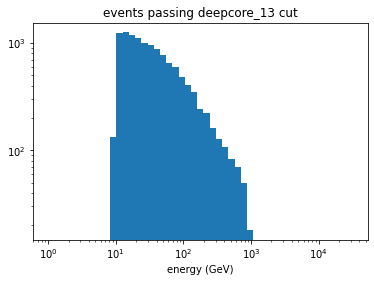

In [5]:
binning = np.logspace(0, 4.5, 50)
plt.hist(db['energy'], bins=binning)

plt.xscale('log')
plt.yscale('log')
plt.xlabel('energy (GeV)')
plt.title('events passing deepcore_13 cut')

In [6]:
# make quality cuts - check for DeepCore filter passed
# min_sep_length = 5
min_energy = 10

# Specify the name of the database file
quality_cut_filelist = dataset_paths
table_name = 'truth'

# cuts = [
#     "dbang_decay_length < %d"%min_sep_length,
#        ]
cuts = [
    "DeepCoreFilter_13 == 0",
#     "energy < %d"%min_energy,
]

for database_file in quality_cut_filelist:
    # Connect to the database
    with sqlite3.connect(database_file) as connection:
        cursor = connection.cursor()

        # Delete rows that do not match the specified conditions
        for cut in cuts: 
            delete_query = f"DELETE FROM {table_name} WHERE %s"%cut
            cursor.execute(delete_query)

        # Commit the changes
        connection.commit()

        # Optional: Get the count of rows affected
        print(f"Rows deleted: {cursor.rowcount}")

    # Connection is automatically closed when exiting the with-statement

Rows deleted: 0
Rows deleted: 0
Rows deleted: 0
Rows deleted: 0


In [ ]:
# Check changes
connection = sqlite3.connect(dataset_paths[0]) 
sql_query="SELECT * from truth"

db = pd.read_sql(sql_query, connection)
db['energy'].head()

In [24]:
### Add an is_hnl columns, marks true for HNL files
for file in dataset_paths:
    # Connecting to sqlite
    connection_obj = sqlite3.connect(file)

    # cursor object
    cursor = connection_obj.cursor()

    # Add a new column to table
    try:
        new_column = "ALTER TABLE truth ADD COLUMN is_hnl BOOLEAN"
        cursor.execute(new_column)
    except:
        print("column was already there")
    finally:
        cursor.execute("UPDATE truth SET is_hnl = 1")
        connection_obj.commit()

        # Close the connection
        connection_obj.close()

column was already there


In [29]:
### Add an is_hnl columns, marks false for background files
for file in background_paths:
    # Connecting to sqlite
    connection_obj = sqlite3.connect(file)

    # cursor object
    cursor = connection_obj.cursor()

    # Add a new column to table
    try:
        new_column = "ALTER TABLE truth ADD COLUMN is_hnl BOOLEAN"
        cursor.execute(new_column)
    except:
        print("column was already there")
    finally:
        cursor.execute("UPDATE truth SET is_hnl = 0")
        connection_obj.commit()

        # Close the connection
        connection_obj.close()

In [30]:
# Check changes
connection = sqlite3.connect(background_paths[0]) 
sql_query="SELECT * from truth"

db = pd.read_sql(sql_query, connection)
db['is_hnl'].head()

0    0
1    0
2    0
3    0
4    0
Name: is_hnl, dtype: int64

In [1]:

from icecube.icetray import I3Tray
from icecube import icetray, dataio, dataclasses, LeptonInjector
from icecube import tableio, hdfwriter
from I3Tray import I3Units

/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_8_x86_64/lib/python3.7/importlib/_bootstrap.py:219: RuntimeWarning: to-Python converter for std::vector<char, std::allocator<char> > already registered; second conversion method ignored.
  return f(*args, **kwds)
/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_8_x86_64/lib/python3.7/importlib/_bootstrap.py:219: RuntimeWarning: to-Python converter for std::vector<std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >, std::allocator<std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> > > > already registered; second conversion method ignored.
  return f(*args, **kwds)
/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_8_x86_64/lib/python3.7/importlib/_bootstrap.py:219: RuntimeWarning: to-Python converter for std::vector<OMKey, std::allocator<OMKey> > already registered; second conversion method ignored.
  return f(*args, **kwds)
/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_8_x8

In [5]:
try: from tqdm import tqdm
except: tqdm = lambda x: x

from collections import OrderedDict


In [10]:
event_properties_keys = [
    "decay_channel", #integer values corresponsing to HNL decay mose
    "distance",      #decay length of the HNL
    "distanceMax",   #Maximum allowed "distance" value
    "distanceMin",   #Minimum allowed "distance" value
    "finalStateX",   #Bjorken X
    "finalStateY",   #Inelasticity
    "final_state_particle0", #PDG code for final state particles
    "final_state_particle1",
    "primary_type",  #PDG code for initial particles ( (-)15 for tau (anti-)neutrinos)
    "lifetime",      #HNL lifetime
    "mHNL",          #HNL mass - a constant value chosen by user - 0.1, 0.3, 0.6, 1.0 GeV
    "outgoing_neutrino_energy",
    "totalEnergy",  
    "physical",      #Is this particle physically possible? Should always be 1
    "total_column_depth"
]

def get_event_properties(files, nfiles=None):
    the_properties = OrderedDict(zip(event_properties_keys, [list() for key in event_properties_keys]))
    properties_df = pd.DataFrame(columns=event_properties_keys)
    if nfiles is None: nfiles = len(files)

    # Loop over the files
    for f in files:
        i3file = dataio.I3File(f)
        
        # And loop through frames for this file
        while i3file.more():
            frame = i3file.pop_frame()
            if frame.Stop != icetray.I3Frame.DAQ: \
                continue
            event_properties = frame["EventProperties"]

            the_properties["mHNL"].append(event_properties.mHNL)
            the_properties["distance"].append(event_properties.distance)
            the_properties["distanceMin"].append(event_properties.distanceMin)
            the_properties["distanceMax"].append(event_properties.distanceMax)
            the_properties["lifetime"].append(event_properties.lifetime)
            the_properties["totalEnergy"].append(event_properties.totalEnergy)
            the_properties["finalStateX"].append(event_properties.finalStateX)
            the_properties["finalStateY"].append(event_properties.finalStateY)
            the_properties['primary_type'].append(event_properties.initialType)
            the_properties['final_state_particle0'].append(event_properties.finalType1)
            the_properties['final_state_particle1'].append(event_properties.finalType2)
            the_properties['total_column_depth'].append(event_properties.totalColumnDepth)
            the_properties["decay_channel"].append(event_properties.decay_channel)
            the_properties["outgoing_neutrino_energy"].append(event_properties.outgoingNeutrinoEnergy)
            the_properties["physical"].append(event_properties.physical)
#             print(the_properties)
            
    return the_properties


In [18]:
file = '/n/holylfs05/LABS/arguelles_delgado_lab/Everyone/jbook/double_cascade_identification/scripts/junk_test_file.i3.zst'

props = get_event_properties([file])


(array([9.021e+03, 1.764e+03, 7.340e+02, 4.200e+02, 2.690e+02, 1.800e+02,
        1.270e+02, 1.040e+02, 6.000e+01, 6.500e+01, 5.200e+01, 3.300e+01,
        4.000e+01, 3.700e+01, 3.000e+01, 2.800e+01, 1.700e+01, 1.600e+01,
        1.900e+01, 1.800e+01, 1.200e+01, 1.600e+01, 1.000e+01, 1.000e+01,
        5.000e+00, 8.000e+00, 6.000e+00, 5.000e+00, 1.200e+01, 9.000e+00,
        8.000e+00, 4.000e+00, 6.000e+00, 9.000e+00, 7.000e+00, 2.000e+00,
        4.000e+00, 3.000e+00, 5.000e+00, 5.000e+00, 6.000e+00, 4.000e+00,
        1.000e+00, 3.000e+00, 3.000e+00, 4.000e+00, 1.000e+00, 2.000e+00,
        4.000e+00, 0.000e+00, 3.000e+00, 4.000e+00, 2.000e+00, 0.000e+00,
        0.000e+00, 2.000e+00, 1.000e+00, 1.000e+00, 2.000e+00, 3.000e+00,
        0.000e+00, 0.000e+00, 2.000e+00, 3.000e+00, 0.000e+00, 1.000e+00,
        2.000e+00, 1.000e+00, 3.000e+00, 2.000e+00, 1.000e+00, 0.000e+00,
        0.000e+00, 2.000e+00, 1.000e+00, 1.000e+00, 2.000e+00, 0.000e+00,
        1.000e+00, 1.000e+00, 1.000e+0

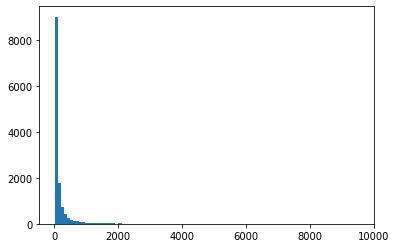

In [20]:
plt.hist(props['totalEnergy'], bins=100)

In [21]:
min(props['totalEnergy'])

10.00193864034862